# Explaining Instant EMI-Finance Decisions
Responsible and Safe AI (AIML4001) - Set B - German Credit (UCI Statlog)

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

## Task 1: Load, encode and split

In [2]:
os.makedirs("outputs", exist_ok=True)
df = pd.read_csv("data/german_credit.csv")
y = (df["class"] == "bad").astype(int)
X_raw = df.drop(columns="class")
cat_cols = [c for c in X_raw.columns if not pd.api.types.is_numeric_dtype(X_raw[c])]
features = list(X_raw.columns)

encoder = OrdinalEncoder()
X = X_raw.copy()
X[cat_cols] = encoder.fit_transform(X_raw[cat_cols])
X = X.astype(float)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## Task 2: Random Forest

In [3]:
model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
acc = accuracy_score(y_test, pred)
auc = roc_auc_score(y_test, proba)
print("Dataset : German Credit (UCI Statlog),", len(df), "applicants,", X.shape[1], "attributes")
print("Model : RandomForest (200 trees, depth 8)")
print(f"Test accuracy : {acc:.2f}      ROC-AUC : {auc:.2f}")

Dataset : German Credit (UCI Statlog), 1000 applicants, 20 attributes
Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.77      ROC-AUC : 0.83


## Task 3: SHAP global importance


GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK  FEATURE              MEAN|SHAP|
---------------------------------------
 1    checking_status        0.092
 2    duration               0.042
 3    credit_amount          0.027
 4    savings_status         0.027
 5    purpose                0.025
---------------------------------------


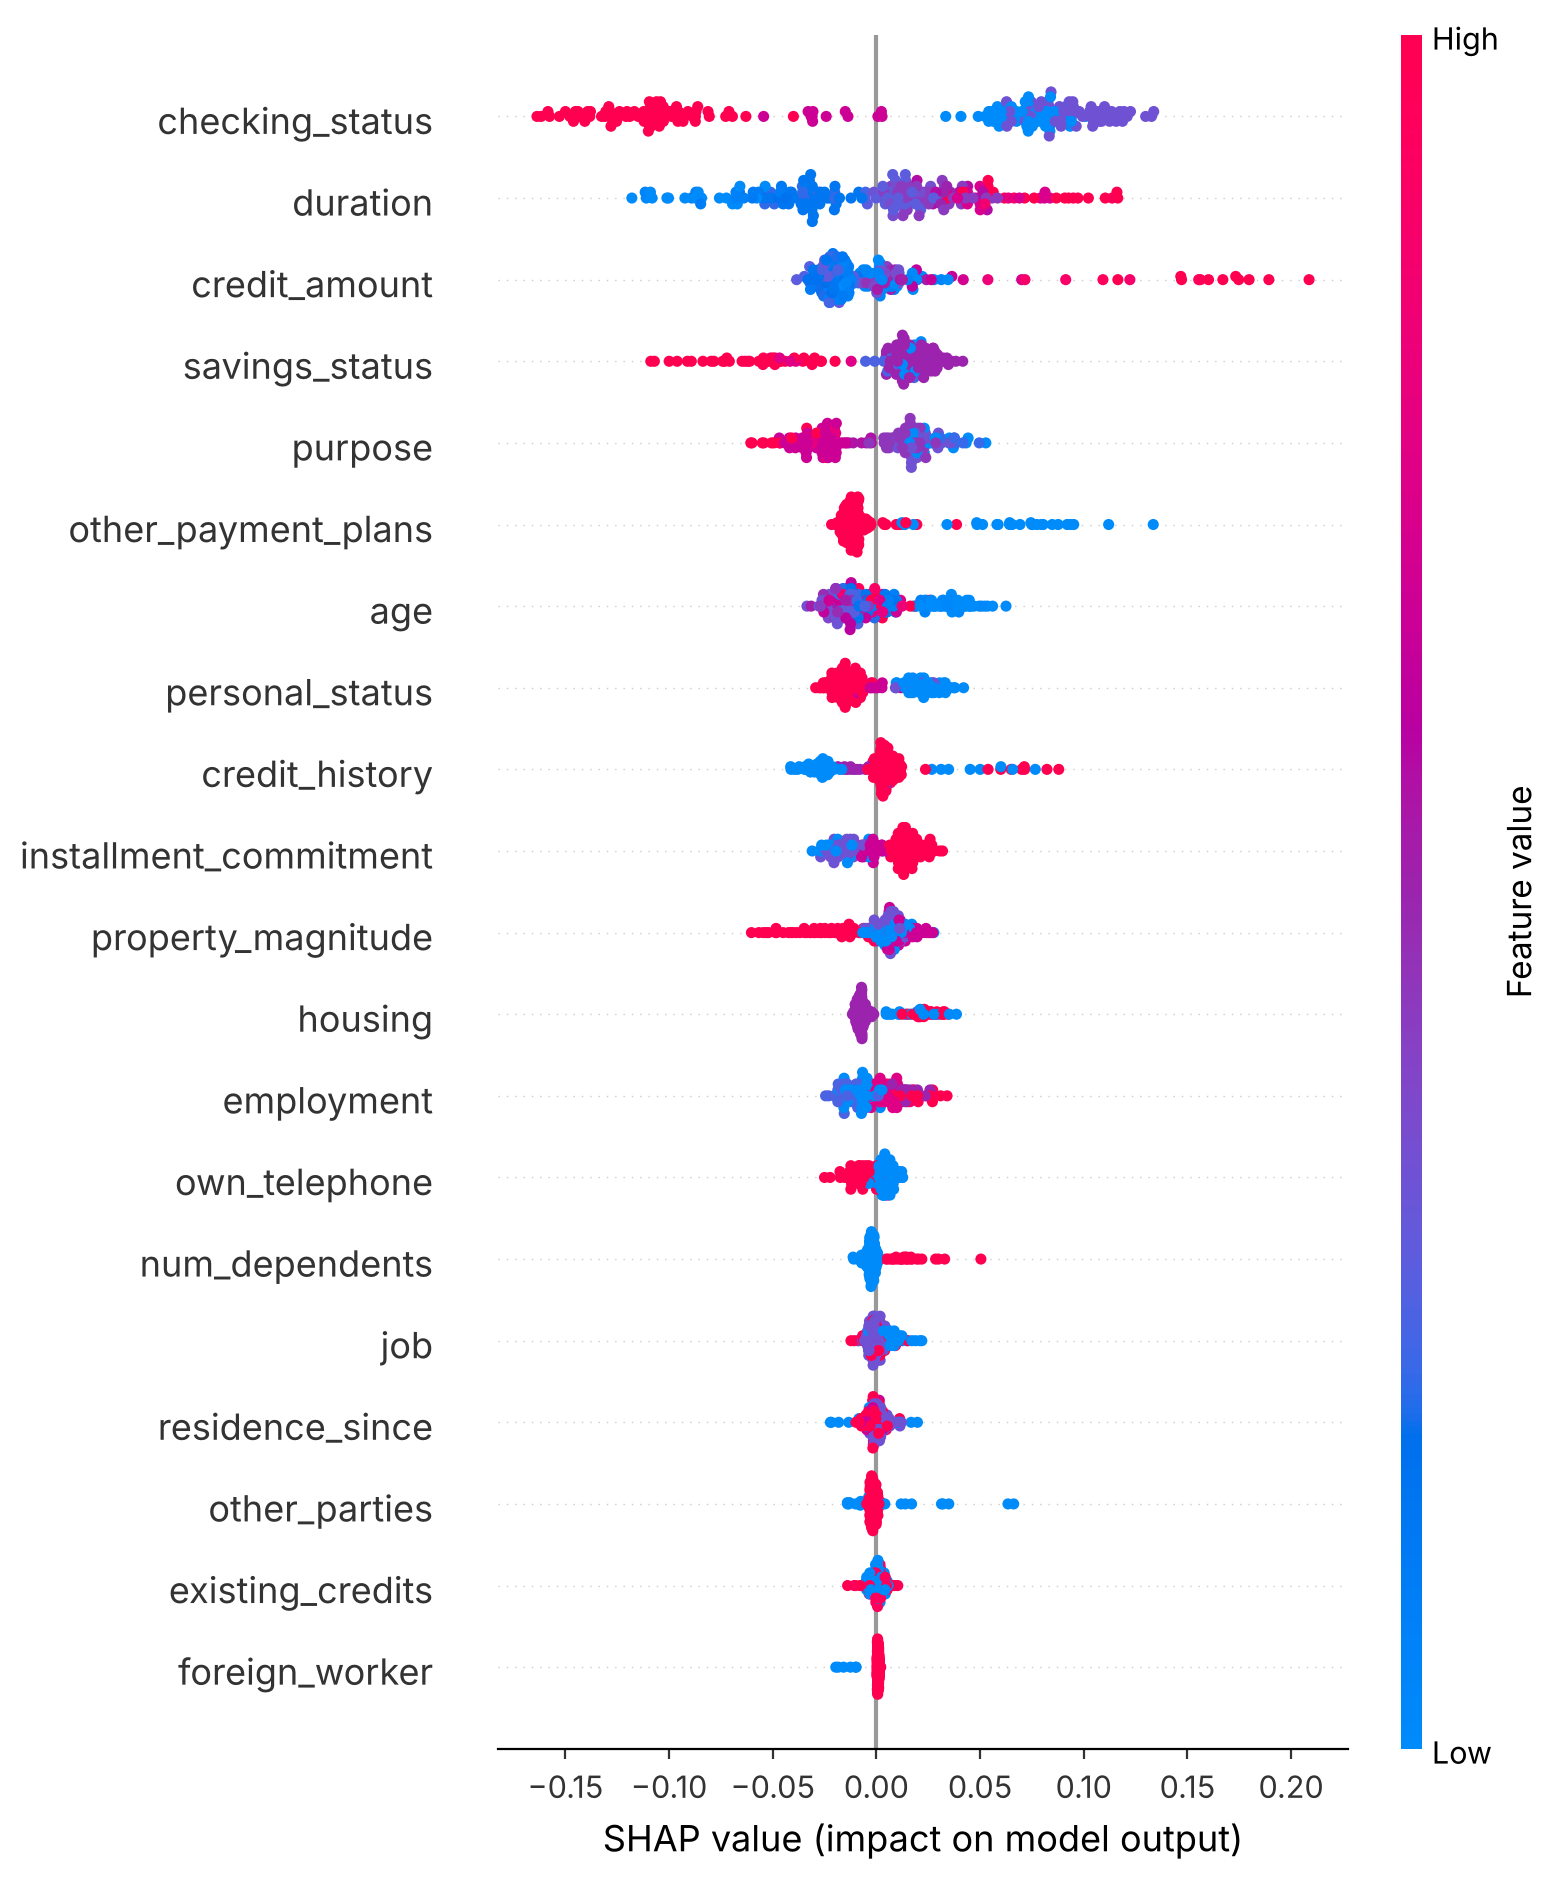

Plot saved : shap_summary.png


In [4]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)[:, :, 1]
base_value = explainer.expected_value[1]
importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=features).sort_values(ascending=False)
top5 = importance.head(5)

print("\nGLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print("RANK  FEATURE              MEAN|SHAP|")
print("-" * 39)
for rank, (feature, value) in enumerate(top5.items(), 1):
    print(f" {rank:<4} {feature:<20} {value:7.3f}")
print("-" * 39)

shap.summary_plot(shap_values.values, X_test, show=False)
plt.savefig("outputs/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved : shap_summary.png")

## Task 4: SHAP waterfall for one rejected applicant

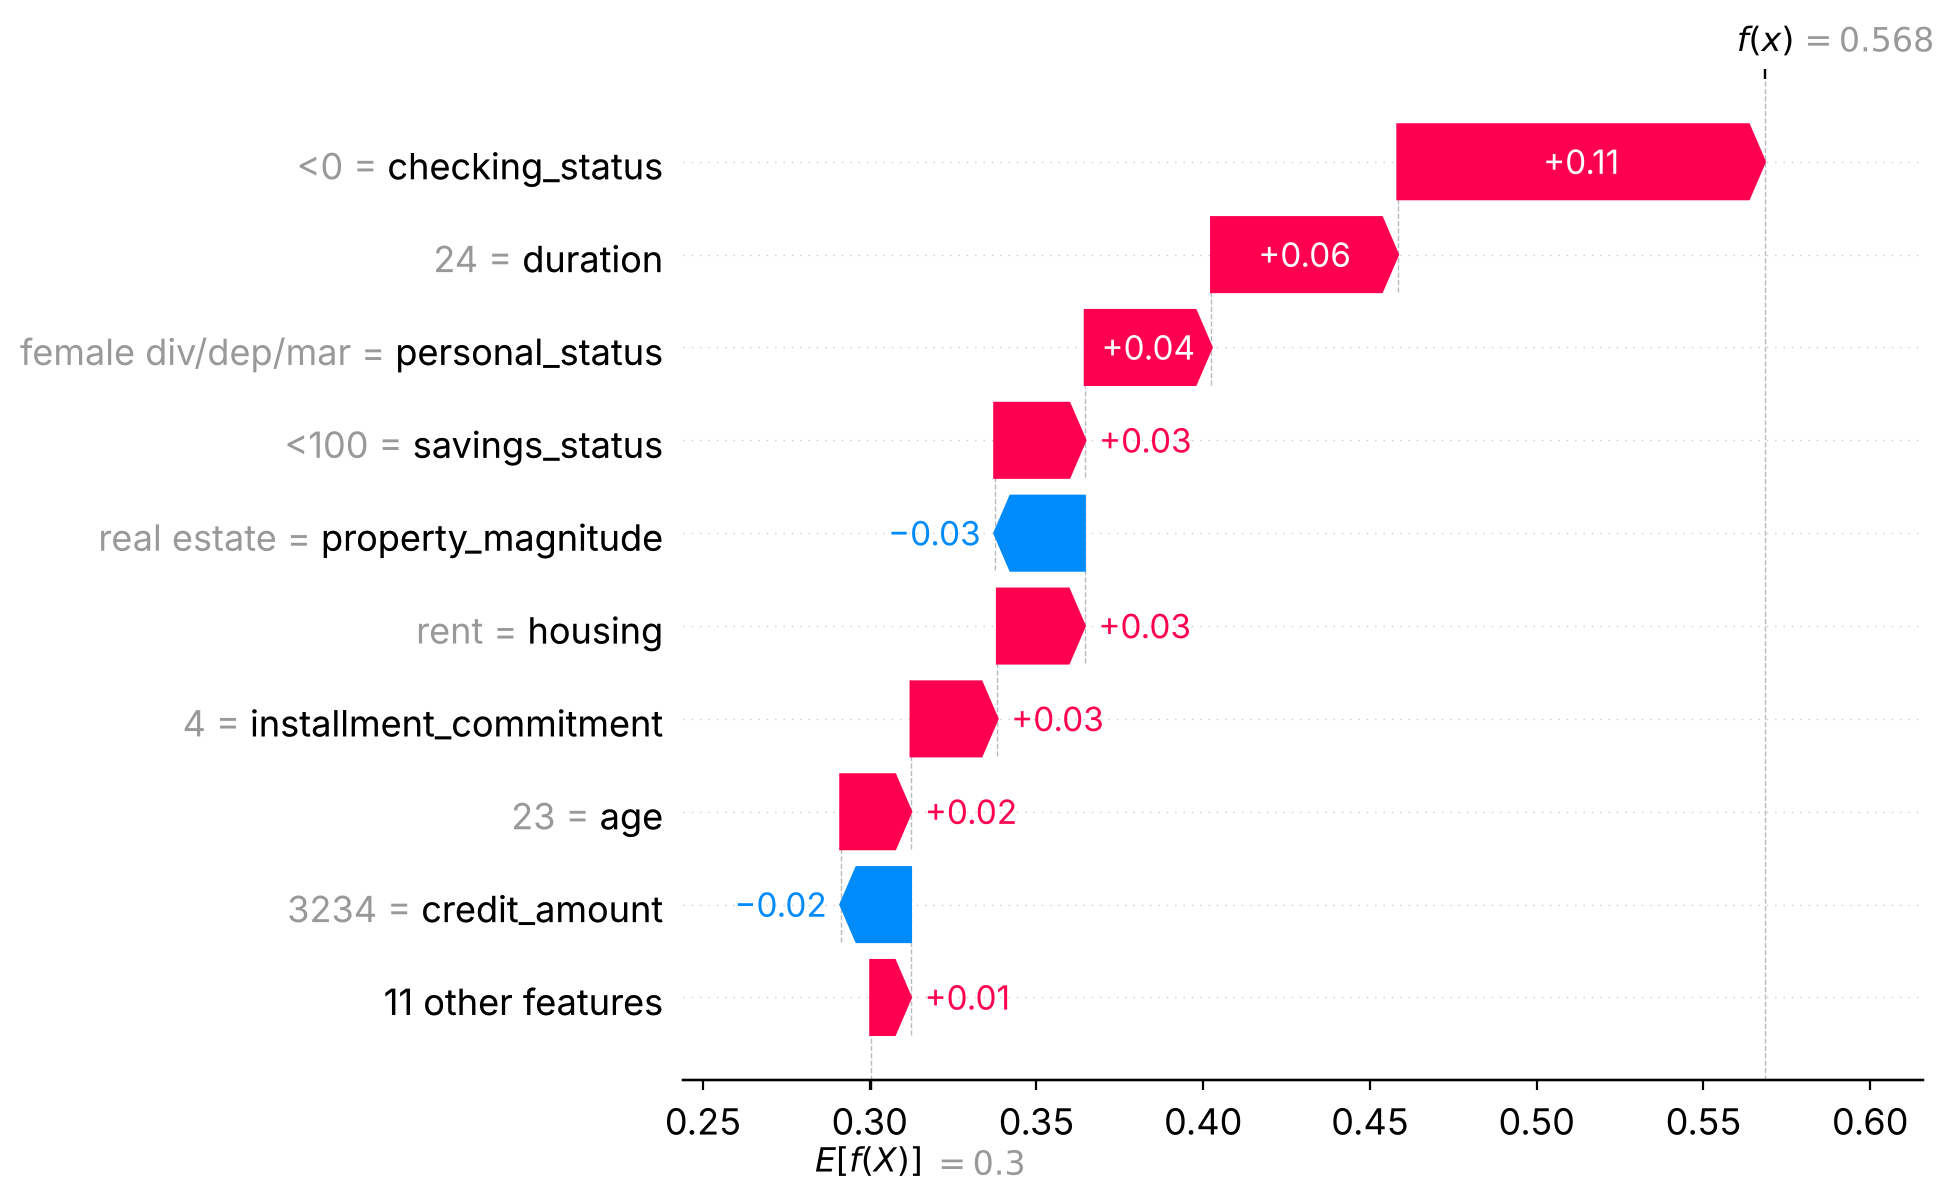

In [5]:
i = int(np.where(pred == 1)[0][0])
row = X_raw.loc[X_test.index[i]]
phi = shap_values.values[i]
order = np.argsort(-phi)
shap_top3 = [features[j] for j in order[:3]]

shap.plots.waterfall(shap.Explanation(phi, base_value, row.values, feature_names=features), show=False)
plt.savefig("outputs/shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 5: LIME and comparison with SHAP

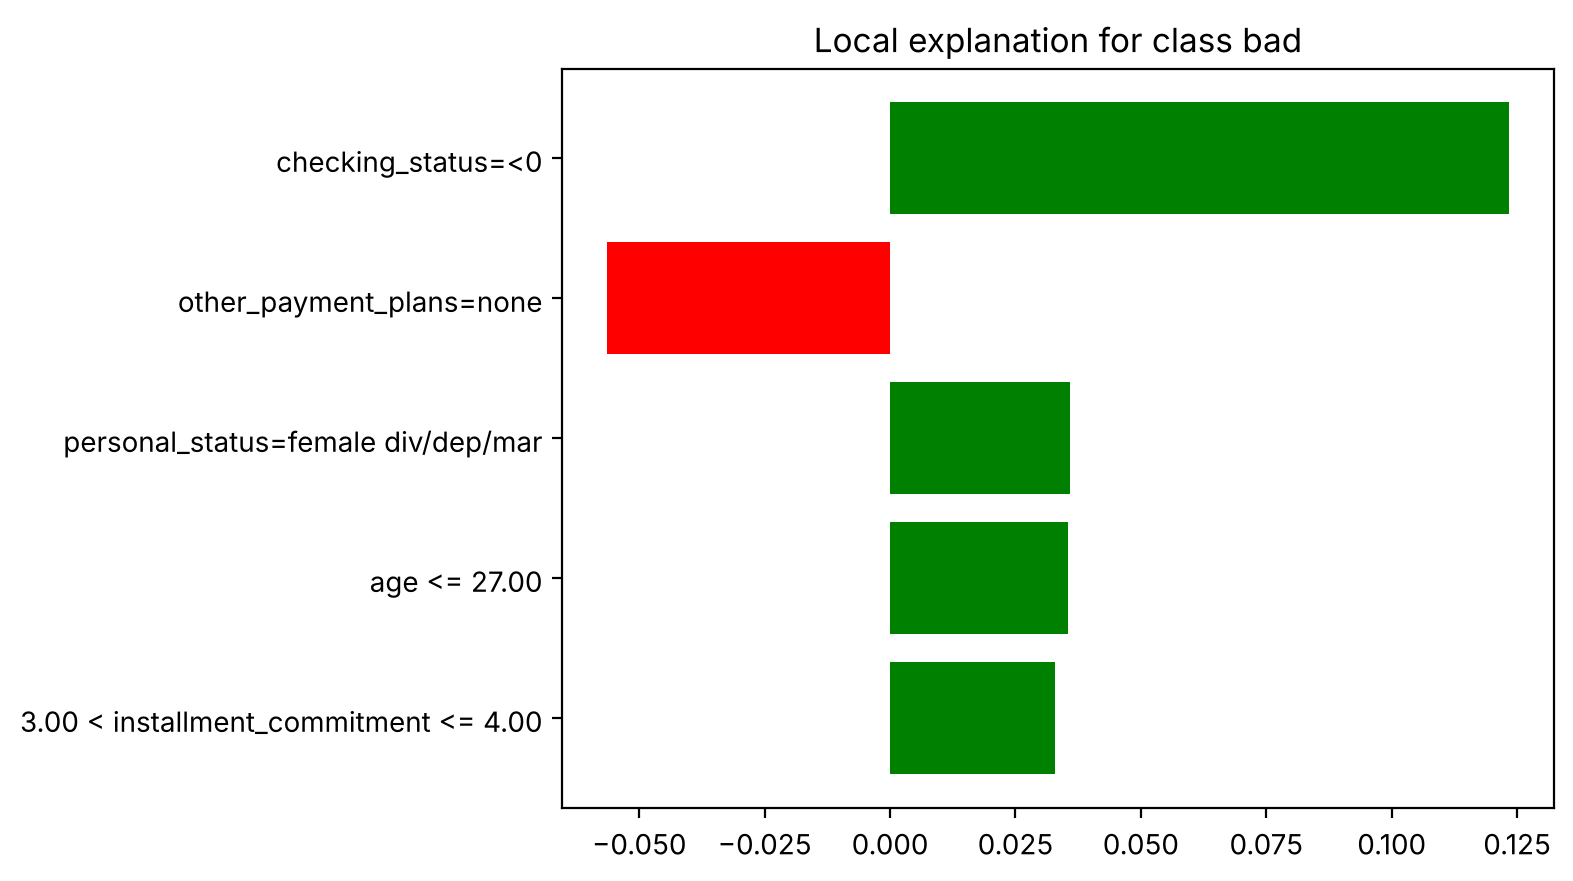


Applicant (test index 23) : P(bad) = 0.57  ->  REJECTED

SHAP (top 3)                                  LIME (top 5)
------------------------------------------------------------------------------------------
checking_status=<0                     +0.11  checking_status=<0                     +0.12
duration=24                            +0.06  other_payment_plans=none               -0.06
personal_status=female div/dep/mar     +0.04  personal_status=female div/dep/mar     +0.04
                                              age <= 27.00                           +0.04
                                              3.00 < installment_commitment <= 4.00  +0.03
------------------------------------------------------------------------------------------
Top-3 agreement (SHAP vs LIME) : 2 / 3  (checking_status, personal_status)


In [6]:
lime_explainer = LimeTabularExplainer(
    X_train.values,
    feature_names=features,
    class_names=["good", "bad"],
    categorical_features=[features.index(c) for c in cat_cols],
    categorical_names={features.index(c): list(cats) for c, cats in zip(cat_cols, encoder.categories_)},
    random_state=42,
)
predict = lambda a: model.predict_proba(pd.DataFrame(a, columns=features))
lime_exp = lime_explainer.explain_instance(X_test.values[i], predict, num_features=5, labels=(1,), num_samples=5000)
lime_rules = lime_exp.as_list(label=1)
lime_feats = [features[j] for j, w in lime_exp.as_map()[1]]
lime_exp.as_pyplot_figure(label=1)
plt.savefig("outputs/lime_explanation.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nApplicant (test index {i}) : P(bad) = {proba[i]:.2f}  ->  REJECTED")
print(f"\n{'SHAP (top 3)':<45} LIME (top 5)")
print("-" * 90)
for k in range(5):
    left = f"{shap_top3[k]}={row[shap_top3[k]]}" if k < 3 else ""
    left = f"{left:<38} {phi[order[k]]:+.2f}" if k < 3 else ""
    print(f"{left:<45} {lime_rules[k][0]:<38} {lime_rules[k][1]:+.2f}")
print("-" * 90)

agree = set(shap_top3) & set(lime_feats[:3])
print(f"Top-3 agreement (SHAP vs LIME) : {len(agree)} / 3  ({', '.join(sorted(agree))})")

## Task 6: Sensitive attributes and rejection message

In [7]:
sensitive = ["age", "personal_status", "foreign_worker"]
reasons = shap_top3 + [features[j] for j, w in lime_exp.as_map()[1] if w > 0]
found = [f for f in sensitive if f in reasons]
print("Sensitive attributes in reasons :", ", ".join(found) + " -> REVIEW" if found else "none -> OK")

phrases = {
    "checking_status": {"<0": "your current account balance is negative",
                        "0<=X<200": "your current account balance is low"}.get(row["checking_status"]),
    "duration": f"the requested duration ({row['duration']} months) is long",
    "credit_amount": f"the requested amount ({row['credit_amount']} DM) is high",
    "savings_status": "your savings balance is low",
}
legit = [f for f in features if phi[features.index(f)] > 0 and f not in sensitive and phrases.get(f)]
legit = sorted(legit, key=lambda f: -phi[features.index(f)])[:2]
message = "Your EMI request was not approved mainly because " + " and ".join(phrases[f] for f in legit) + "."
print(f'\nMessage (legitimate reasons only): "{message}"')

Sensitive attributes in reasons : age, personal_status -> REVIEW

Message (legitimate reasons only): "Your EMI request was not approved mainly because your current account balance is negative and the requested duration (24 months) is long."
